# <font color="greenyellow" size="7"><b>VISION TRANSFORMER (VIT)</b></font>

<font color="greenyellow" size="5"><b>Detección de <i>Ochroma pyramidale</i> · cuaderno paso a paso</b></font>

Este cuaderno entrena el **Vision Transformer (ViT)** de la tesis, paso a paso, con la misma receta de tu cuaderno Ultima_prueba_VIT (celdas «creadores»): copas del watershed, recorte de cada copa en color natural a 224 px, corte 70/30 y 150 épocas desde ImageNet. Necesita GPU.

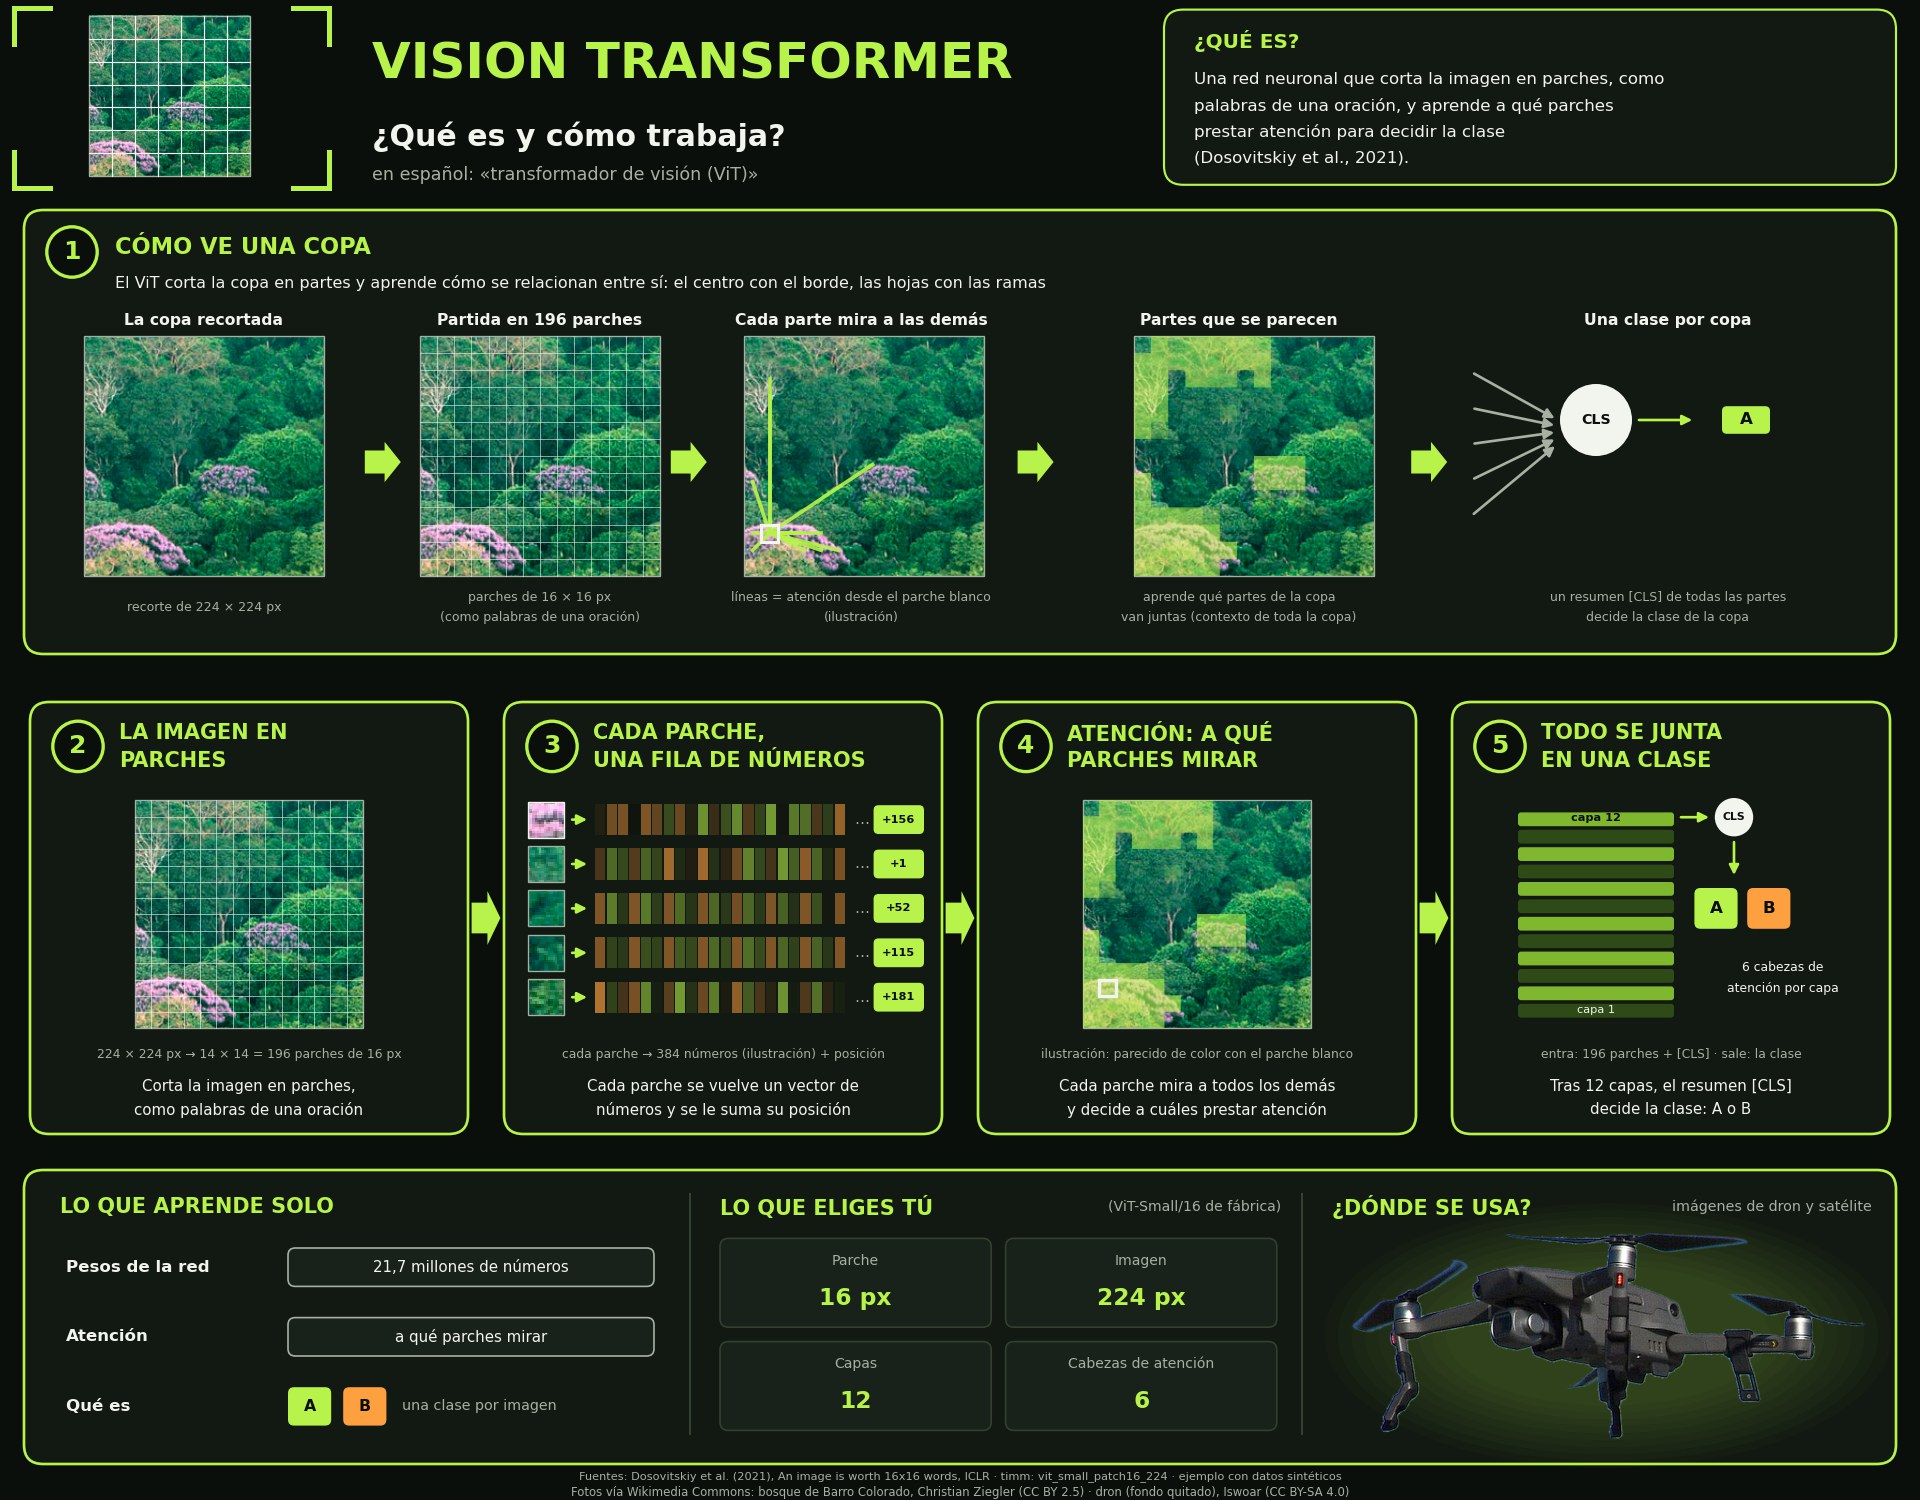

**Pasos:** **1** Conectar Drive y cargar las herramientas · **2** Rutas y parámetros · **3** Abrir el ortomosaico y ver tus polígonos · **4** Separar las copas (watershed del ViT) · **5** Etiquetar cada copa · **6** Dividir: 70 % aprende, 30 % valida · **7** Recortar cada copa (parches de 224 px) · **8** Solo si Colab se reinició: recuperar los parches · **9** Entrenar el ViT · **10** Examen en el 30 % · **11** Detectar en todo el ortomosaico · **12** Mapa final (tú eliges el estilo) · **13** Ortomosaico interactivo con barra de umbral · **14** Guardar las copas del umbral que elegiste

**Cómo usarlo:** corre las celdas en orden con ▶. Solo se cambia el **Paso 2** (rutas y parámetros); el resto ya está listo.

## <font color="greenyellow" size="6"><b>PASO 1 · Conectar Drive y cargar las herramientas</b></font>
**Para qué:** que Colab lea tus datos, instalar lo que necesita esta red y cargar las funciones de cada paso (`topa_pasos.py`).  
**Qué verás:** «Mounted at /content/drive». Antes de empezar: Entorno de ejecución → Cambiar tipo → GPU.

In [2]:
from google.colab import drive; drive.mount("/content/drive")
!pip install -q rasterio timm
import sys; sys.path.append("/content/drive/MyDrive/PASO_A_PASO")
from topa_pasos import *
estilo_figuras(tam_letra=11, fuente="DejaVu Sans")     # letra de TODAS las figuras: tamaño y tipo
# los colores se escriben con su nombre: verde, rojo, amarillo, azul, negro… (para verlos todos: ver_colores())

Mounted at /content/drive


## <font color="greenyellow" size="6"><b>PASO 2 · Rutas y parámetros</b></font>
**Para qué:** decir dónde están tus datos y dónde se guarda lo que salga. Es lo único que se cambia.

In [3]:
ORTO = "/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/ortomosaico_TOPA.tif"
SHP = "/content/drive/MyDrive/SHP_3/SHP_topa.shp"
CAMPO, TOPA = "ESPECIE", "1"                                   # campo de especie y valor que es topa
SALIDA = "/content/drive/MyDrive/PASO_A_PASO/RESULTADOS_VIT"     # aquí quedan el modelo y el mapa
PARCHES = f"{SALIDA}/parches_rgb_creadores.npz"     # recortes de cada copa
MODELO = f"{SALIDA}/vit_rgb_creadores.pt"           # aquí queda la red entrenada

## <font color="greenyellow" size="6"><b>PASO 3 · Abrir el ortomosaico y ver tus polígonos</b></font>
**Para qué:** comprobar que los datos son los correctos antes de entrenar.  
**Qué verás:** el ortomosaico con tus topas (celeste) y otras especies (magenta), completo y acercado.

In [4]:
src = abrir_orto(ORTO)
shp = leer_poligonos(SHP, src, CAMPO, TOPA)
ver_mapa(src, [capa(shp[shp.cl == 1], relleno="ninguno", borde="celeste", etiqueta="topa", grosor=0.6),
               capa(shp[shp.cl == 2], relleno="ninguno", borde="magenta", etiqueta="otras especies", grosor=0.6)],
         titulo="Tus polígonos", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", zona=zona_topas(shp))

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 4 · Separar las copas (watershed del ViT)</b></font>
**Para qué:** dividir el bosque en copas; cada copa será una muestra para la red.  
**Qué verás:** cuántas copas salieron y sus bordes amarillos sobre el ortomosaico.

> NDVI_MIN = verdor mínimo · MIN_DIST = distancia mínima entre centros (en píxeles de la imagen reducida a 4000) · SIGMA = suavizado · AREA = tamaño de copa en m².

In [5]:
gw = vit_watershed(src, MAXDIM=4000, MIN_DIST=18, SIGMA=2, NDVI_MIN=0.3, AREA_MIN=2, AREA_MAX=200)
ver_mapa(src, [capa(gw, relleno="ninguno", borde="amarillo", etiqueta="copas", grosor=0.6)],
         titulo="Copas del watershed", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", zona=zona_topas(shp))

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 5 · Etiquetar cada copa</b></font>
**Para qué:** darle a cada copa la clase del polígono con el que más se solapa; las no topa se reducen a 5 por cada topa.  
**Qué verás:** topa en verde y no topa en rojo.

In [6]:
gw, topa = vit_etiquetar(gw, SHP, src, CAMPO, TOPA, NEG_X=5)
ver_mapa(src, [capa(gw[gw.y == 1], relleno="rojo", borde="negro", etiqueta="no topa", grosor=0.1, transparencia=0.6),
               capa(gw[gw.y == 0], relleno="verde", borde="negro", etiqueta="topa", grosor=0.1, transparencia=0.9)],
         titulo="Clase de cada copa", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha")

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 6 · Dividir: 70 % aprende, 30 % valida</b></font>
**Para qué:** separar las copas con una línea Norte–Sur por el 70 % de las topas.  
**Qué verás:** cuántas copas quedan a cada lado y el mapa: celeste aprende, naranja valida.  
**Fuente:** 70/30 del proyecto; corte espacial para que el examen sea en otra zona (Htun et al. 2026).

In [7]:
gw, CORTE = vit_corte(gw, topa, SPLIT_PCT=0.70)
ver_mapa(src, [capa(gw[gw.split == 0], relleno="celeste", borde="negro", etiqueta="70 % aprende", grosor=0.1, transparencia=0.6),
               capa(gw[gw.split == 1], relleno="naranja", borde="negro", etiqueta="30 % valida", grosor=0.1, transparencia=0.6)],
         titulo="División 70/30", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", linea=("y", CORTE), color_linea="rojo")

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 7 · Recortar cada copa (parches de 224 px)</b></font>
**Para qué:** recortar el recuadro de cada copa en color natural y llevarlo a 224 × 224 px, el tamaño con que se preentrenó el ViT.  
**Qué verás:** 8 parches de topa (arriba) y 8 de no topa (abajo).  
**Fuente:** 224 px: Huang et al. (2023).

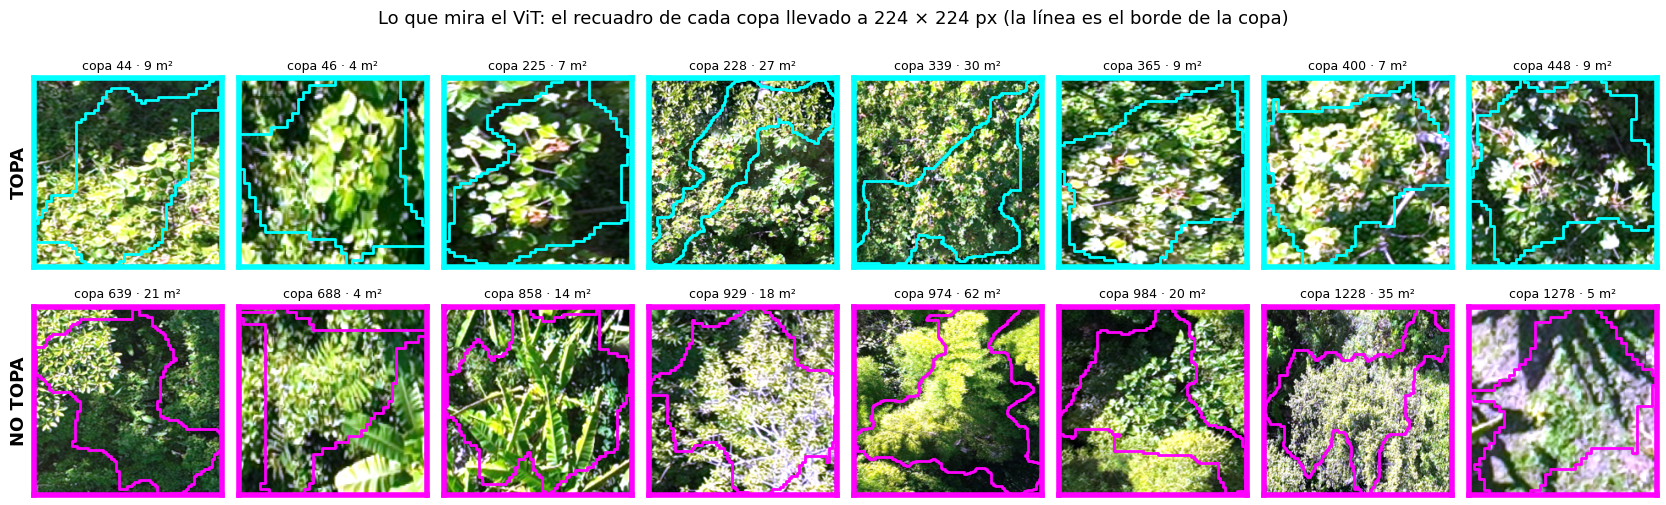

1427 parches guardados en /content/drive/MyDrive/PASO_A_PASO/RESULTADOS_VIT/parches_rgb_creadores.npz


In [8]:
X, Y, S = vit_parches(src, gw, PARCHES, CANALES=(1, 2, 3), PATCH=224)

## <font color="greenyellow" size="6"><b>PASO 8 · Solo si Colab se reinició: recuperar los parches</b></font>
**Para qué:** seguir sin volver a recortar: lee los parches que el paso anterior guardó en tu Drive.  
**Qué verás:** cuántos parches recuperó: los que aprenden y los que validan, de topa y de no topa.

> Si Colab se desconectó, corre el Paso 1 y el Paso 2, luego esta celda, y sigue con «Entrenar el ViT». Si ya habías entrenado, salta al examen: la red ya está guardada en tu Drive. Si Colab no se reinició, puedes saltar esta celda.

In [9]:
X, Y, S = cargar_parches(PARCHES)

1427 parches recuperados · aprende 1050 · valida 377 · topa 524 · no topa 903


## <font color="greenyellow" size="6"><b>PASO 9 · Entrenar el ViT</b></font>
**Para qué:** ajustar un Vision Transformer pequeño (ViT-Small/16, preentrenado en ImageNet) con los parches del 70 %; en cada época se mide el Kappa en el 30 % y se guarda la mejor.  
**Qué verás:** el Kappa de cada época y la curva de aprendizaje. Tarda alrededor de una hora en GPU.  
**Fuente:** 224 px, 150 épocas, AdamW y wd 0,05: Huang et al. (2023); lr 5e-5 y coseno: Endres et al. (2026); normalización de ImageNet: Ramesh et al.; volteos y brillo: Huang et al. (2023); pesos por clase N/(2·Nc): scikit-learn. Lote 32 y ganancia por canal: criterio de la tesis.

> La mejor época se elige con el mismo 30 % del examen, como en la tesis (limitación declarada).

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

época 001 · Kappa 0.763 (mejor 0.763)
época 002 · Kappa 0.879 (mejor 0.879)
época 003 · Kappa 0.870 (mejor 0.879)
época 004 · Kappa 0.901 (mejor 0.901)
época 005 · Kappa 0.855 (mejor 0.901)
época 006 · Kappa 0.702 (mejor 0.901)
época 007 · Kappa 0.913 (mejor 0.913)
época 008 · Kappa 0.934 (mejor 0.934)
época 009 · Kappa 0.929 (mejor 0.934)
época 010 · Kappa 0.923 (mejor 0.934)
época 011 · Kappa 0.929 (mejor 0.934)
época 012 · Kappa 0.773 (mejor 0.934)
época 013 · Kappa 0.865 (mejor 0.934)
época 014 · Kappa 0.912 (mejor 0.934)
época 015 · Kappa 0.918 (mejor 0.934)
época 016 · Kappa 0.907 (mejor 0.934)
época 017 · Kappa 0.855 (mejor 0.934)
época 018 · Kappa 0.935 (mejor 0.935)
época 019 · Kappa 0.913 (mejor 0.935)
época 020 · Kappa 0.901 (mejor 0.935)
época 021 · Kappa 0.885 (mejor 0.935)
época 022 · Kappa 0.902 (mejor 0.935)
época 023 · Kappa 0.895 (mejor 0.935)
época 024 · Kappa 0.889 (mejor 0.935)
época 025 · Kappa 0.906 (mejor 0.935)
época 026 · Kappa 0.917 (mejor 0.935)
época 027 · 

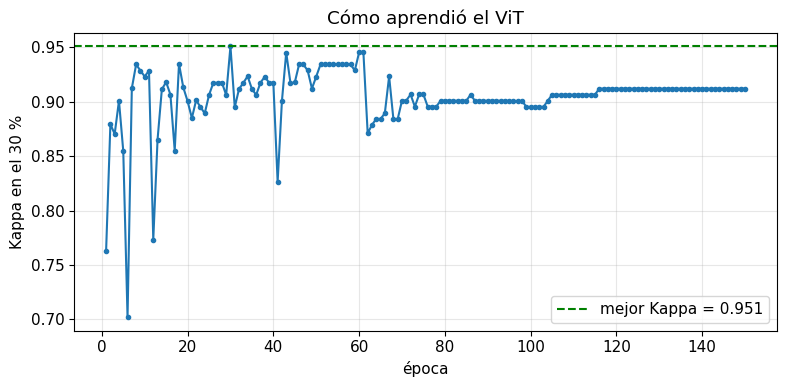

Mejor modelo guardado: /content/drive/MyDrive/PASO_A_PASO/RESULTADOS_VIT/vit_rgb_creadores.pt


In [10]:
MODELO, HIST = entrenar_vit(X, Y, S, MODELO, EPOCHS=150, BS=32, LR=5e-5)

## <font color="greenyellow" size="6"><b>PASO 10 · Examen en el 30 %</b></font>
**Para qué:** medir qué tan bien reconoce la topa en las copas del 30 %.  
**Qué verás:** la tabla de métricas con su intervalo de confianza del 95 %, la matriz de confusión y la curva ROC.  
**Fuente:** clase más probable (umbral 0,50); intervalos por bootstrap (1000 remuestreos).

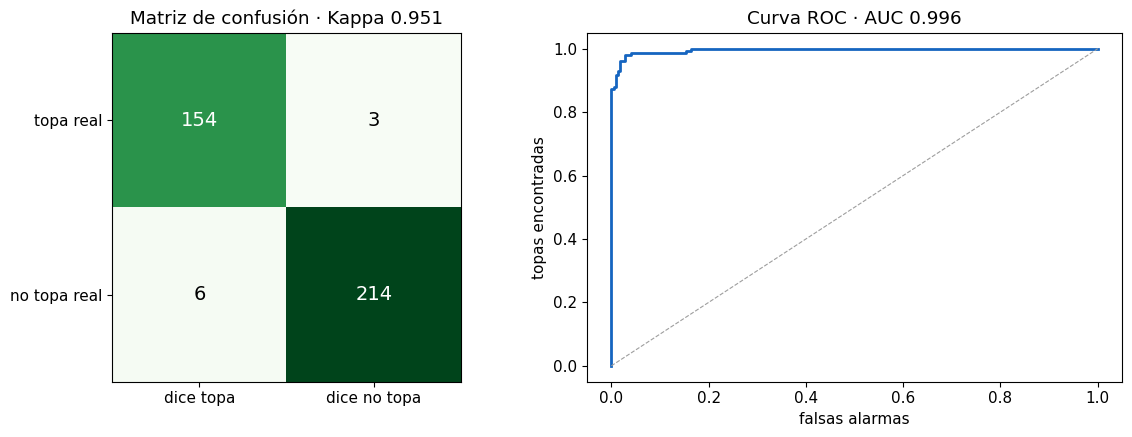

VP 154 · FN 3 · FP 6 · VN 214


,valor,IC95 inferior,IC95 superior
OA,0.976,0.960,0.989
Kappa,0.951,0.920,0.978
Precisión topa,0.962,0.932,0.989
Recall topa,0.981,0.955,1.000
F1 topa,0.972,0.953,0.988
AUC,0.996,0.992,0.999


In [11]:
TAB, MATRIZ, y_p = examen_vit(MODELO, X, Y, S)
display(TAB)

## <font color="greenyellow" size="6"><b>PASO 11 · Detectar en todo el ortomosaico</b></font>
**Para qué:** correr el modelo en todo el ortomosaico y guardar sus copas de topa con su probabilidad.  
**Qué verás:** cuántas copas de topa encontró. Tarda varios minutos.  
**Fuente:** clase que da el modelo con umbral de decisión 0,50 (tutorial de Esri). Copa entera del watershed.

> Para usar el modelo de la tesis en vez del recién entrenado, antes de esta celda escribe: MODELO = "/content/drive/MyDrive/vit_rgb_creadores.pt"

In [12]:
TOP, SHP_TOPA = detectar(MODELO, ORTO, SALIDA)

Corriendo el modelo en todo el ortomosaico (puede tardar varios minutos)…
Modelo vit_rgb_creadores · tipo VIT · orto ortomosaico_TOPA · forma mascaras
Modelo: vit_rgb_creadores (vit_small_patch16_224, 3 canales) · bandas [1, 2, 3] · parche 'recuadro' · normalización imagenet · receta: la de vit_rgb_creadores
orto 12528 × 17318 px a 1.84 cm · separando copas (NIR × (1 + NDVI))…
   4260 copas de 1 a 400 m² · 48 s
   1000/4260 copas · faltan ~0.6 min
   2000/4260 copas · faltan ~0.4 min
   3000/4260 copas · faltan ~0.2 min
   4000/4260 copas · faltan ~0.0 min
Forma «copa entera»: uso las 1419 copas de todo ortomosaico_TOPA ya hechas (/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/copas_entera_ortomosaico_TOPA_d3_a22-79.25.gpkg)
   723 topas del modelo → 723 con forma de copa entera del watershed: 149 con las copas que tienen más de la mitad dentro · 574 con la copa donde cae la mayor parte · 0 fuera de la segmentación (como las marcó el modelo) · 420 caen en las mismas c

## <font color="greenyellow" size="6"><b>PASO 12 · Mapa final (tú eliges el estilo)</b></font>
**Para qué:** dibujar el mapa de presentación. Cambia los valores para elegir el título, las letras, los colores, la leyenda y lo demás.  
**Qué verás:** el mapa con marco, coordenadas en los 4 lados, escala, norte y leyenda; queda guardado en SALIDA. Si solo cambias el estilo, corre esta celda otra vez (no hace falta detectar de nuevo).

> Colores: escríbelos con su nombre en español (verde, rojo, rojo vivo, amarillo, naranja, azul, celeste, morado, rosado, marrón, gris, negro, blanco…) o en inglés (green, red, black…); «ninguno» = sin relleno. Para ver todos los colores: ver_colores(). Lugar de la leyenda: «arriba derecha», «arriba izquierda», «abajo derecha», «abajo izquierda» o «centro». Transparencia: de 0 (invisible) a 1 (opaco).

In [18]:
SHP_TOPA = f"{SALIDA}/topa_vit_rgb_creadores_ortomosaico_TOPA_ws_esri.shp"   # tus copas detectadas en el paso 11
TOP = gpd.read_file(SHP_TOPA)
mapa_final(ORTO, TOP, "ViT", SALIDA,
           titulo="Detección de", especie="Ochroma pyramidale", tam_titulo=13,
           relleno="rojo", transparencia=0.45, borde="amarillo", grosor=0.7,
           titulo_leyenda=None, tam_leyenda=9, pos_leyenda="abajo derecha",
           norte=True, tam_norte=0.6, pos_norte="arriba derecha", fondo_norte="blanco",
           escala=True, largo_escala=None, tramos_escala=4, tam_escala=1.0, pos_escala="abajo izquierda",
           coordenadas=True, tam_coord=8, cada_coord=None, lados_coord="cuatro", sistema=True,
           tam_letra=8, color_marco="negro", ancho=9, dpi=300)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 13 · Ortomosaico interactivo con barra de umbral</b></font>
**Para qué:** mover y acercar el ortomosaico con el ratón y mover la barra de umbral: se ven las copas con probabilidad mayor que el umbral y cuántas son.  
**Qué verás:** la página interactiva. En 0,50 marca las mismas copas que el mapa final. Al pasar el ratón sobre una copa se ve su probabilidad; la otra barra aclara el ortomosaico.

In [13]:
mapa_interactivo(ORTO, SHP_TOPA, umbral=0.50, titulo="Detección de Ochroma pyramidale",
                 relleno="rojo vivo", borde="blanco", transparencia=0.40, grosor=1.2, tam_letra=14, alto=650)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 14 · Guardar las copas del umbral que elegiste</b></font>
**Para qué:** guardar en un SHP (para ArcGIS o QGIS) las copas con probabilidad mayor que el umbral que elegiste en la barra.  
**Qué verás:** cuántas copas pasaron el umbral y dónde quedó el SHP.

> Para el mapa de presentación con ese umbral: mapa_final(ORTO, TOP_U, "ViT", SALIDA, titulo="Detección de", relleno="rojo")

In [ ]:
TOP_U, SHP_U = guardar_umbral(SHP_TOPA, umbral=0.50)      # pon aquí el umbral que elegiste en la barra